# KNN Classification on Breast Cancer Dataset

## Overview
This notebook demonstrates **K-Nearest Neighbors (KNN)** classification on the **Wisconsin Breast Cancer Dataset**. We will:
1. Load and explore the dataset
2. Preprocess the data (scaling features)
3. Train a KNN classifier
4. Evaluate accuracy with different K values
5. Visualize decision boundaries

## Step 1: Import Libraries
Import necessary libraries for data processing, machine learning, and visualization.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

## Step 2: Load and Explore Data
Load the breast cancer dataset and display the first few rows to understand the structure.

In [2]:
df = pd.read_csv('./datasets/Breast-cancer-dataset.csv')
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## Step 3: Clean Data
Remove unnecessary columns:
- **id**: Just an identifier, not useful for prediction
- **Unnamed: 32**: Empty column with no data

In [3]:
df.drop(columns=['id','Unnamed: 32'],inplace=True)
df.head()

/var/folders/36/jp04yqk11pz19cyks4s492tr0000gn/T/ipykernel_19472/3233353923.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['id','Unnamed: 32'],inplace=True)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Step 4: Check Dataset Size
Verify the shape of the cleaned dataset (rows × columns).

In [4]:
df.shape

(569, 31)

## Step 5: Split Data
Divide the dataset into training (80%) and testing (20%) sets to evaluate model performance on unseen data.

### Understanding `random_state=2`
- **`random_state`** controls the ***randomness*** when splitting data into train/test sets
- **`random_state=2`** means we use a specific seed (2) to ensure ***reproducibility***
- With the ***same seed***, the split will always produce the ***same training and test sets***
- This is important for:
  - ***Consistency***: Getting the same results every time you run the notebook
  - ***Comparison***: Comparing different models fairly (same data split)
  - ***Collaboration***: Others can reproduce your exact results
- If we didn't set `random_state`, the split would be different each time we run the code

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.iloc[:,1:], df.iloc[:,0],test_size=0.2, random_state=2)

## Step 6: Inspect Training Data
Display first few rows of training features to understand the data structure.

In [6]:
X_train.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
560,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,0.1537,0.06171,...,15.30,33.17,100.20,706.7,0.1241,0.22640,0.1326,0.10480,0.2250,0.08321
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,11.68,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083
198,19.18,22.49,127.50,1148.0,0.08523,0.14280,0.11140,0.06772,0.1767,0.05529,...,23.36,32.06,166.40,1688.0,0.1322,0.56010,0.3865,0.17080,0.3193,0.09221
203,13.81,23.75,91.56,597.8,0.13230,0.17680,0.15580,0.09176,0.2251,0.07421,...,19.20,41.85,128.50,1153.0,0.2226,0.52090,0.4646,0.20130,0.4432,0.10860
41,10.95,21.35,71.90,371.1,0.12270,0.12180,0.10440,0.05669,0.1895,0.06870,...,12.84,35.34,87.22,514.0,0.1909,0.26980,0.4023,0.14240,0.2964,0.09606


## Step 7: Verify Training Data Shape
Check dimensions of training set (samples × features).

In [7]:
X_train.shape

(455, 30)

## Step 8: Feature Scaling with StandardScaler

Scale features using `StandardScaler` to normalize them. **Why?** KNN uses ***distance calculations***, and features with large scales (e.g., area: 0-2000) would dominate smaller-scale features. Scaling ensures all features contribute equally to distance calculations.

### What is `StandardScaler`?
- A preprocessing tool that ***standardizes features*** by removing the mean and scaling to unit variance
- Formula: $z = \frac{x - \text{mean}}{\text{std}}$ for each feature
- Transforms data so that:
  - **Mean** (average) = 0
  - **Standard Deviation** = 1
  - Result: Values centered around 0 with similar ranges

### Example Transformation:
- **Before**: `area_mean` ranges from 0 to 2000, `radius_mean` ranges from 5 to 30
- **After StandardScaler**: Both ranges become roughly -2 to +2 (standardized)

### What is `fit_transform()`?
- **Two operations combined in one**:
  1. **`fit()`** — Learn the mean and standard deviation FROM the training data
  2. **`transform()`** — Apply those same statistics to scale the data

### Why use separate `fit()` and `transform()`?
- **`scaler.fit_transform(X_train)`** — Fit on training data AND transform it
- **`scaler.transform(X_test)`** — Transform test data using training data's statistics

This prevents ***data leakage***:
- If we fit on the entire dataset (train + test), the model would "see" test data information
- By fitting only on training data, test data remains truly "unseen"
- This ensures honest model evaluation

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Step 9: View Scaled Data
Display the scaled training data. Notice values are now centered near 0 with smaller ranges.

In [9]:
X_train

array([[-0.01330339,  1.7757658 , -0.01491962, ..., -0.13236958,
        -1.08014517, -0.03527943],
       [-0.8448276 , -0.6284278 , -0.87702746, ..., -1.11552632,
        -0.85773964, -0.72098905],
       [ 1.44755936,  0.71180168,  1.47428816, ...,  0.87583964,
         0.4967602 ,  0.46321706],
       ...,
       [-0.46608541, -1.49375484, -0.53234924, ..., -1.32388956,
        -1.02997851, -0.75145272],
       [-0.50025764, -1.62161319, -0.527814  , ..., -0.0987626 ,
         0.35796577, -0.43906159],
       [ 0.96060511,  1.21181916,  1.00427242, ...,  0.8956983 ,
        -1.23064515,  0.50697397]], shape=(455, 30))

## Step 10: Confirm Scaled Data Shape
Verify scaled data maintains correct dimensions.

In [10]:
X_train.shape

(455, 30)

## Step 11: Create KNN Classifier
Initialize a K-Nearest Neighbors classifier with **K = 3**, meaning we'll examine 3 nearest neighbors for predictions. We'll later test different K values to find the optimal one.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)

## Step 12: Train the Model
Fit the KNN classifier on scaled training data. Since KNN is a "lazy learner", it just stores the data rather than learning parameters.

In [12]:
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['B','M']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Step 13: Evaluate Performance
Make predictions on test data and calculate ***accuracy***. Accuracy = (Correct Predictions) / (Total Predictions). An accuracy of 99%+ means the model correctly classifies ~99 out of 100 test samples!

In [13]:
from sklearn.metrics import accuracy_score

y_pred = knn.predict(X_test)

accuracy_score(y_test, y_pred)

0.9912280701754386

## Step 14: Hyperparameter Tuning
Test K values from 1 to 15 to find which K produces the best accuracy. This tests the ***bias-variance tradeoff***:
- **Low K (1-3)**: High variance, may overfit
- **Medium K (5-10)**: Balanced tradeoff  
- **High K (15+)**: High bias, may underfit

In [14]:
scores = []

for i in range(1,16):
    
    knn = KNeighborsClassifier(n_neighbors=i)
    
    knn.fit(X_train,y_train)
    
    y_pred = knn.predict(X_test)

    scores.append(accuracy_score(y_test, y_pred))
    

## Step 15: Visualize K Value Impact
Plot accuracy vs. K value to identify the optimal hyperparameter. Look for the K value where accuracy peaks.

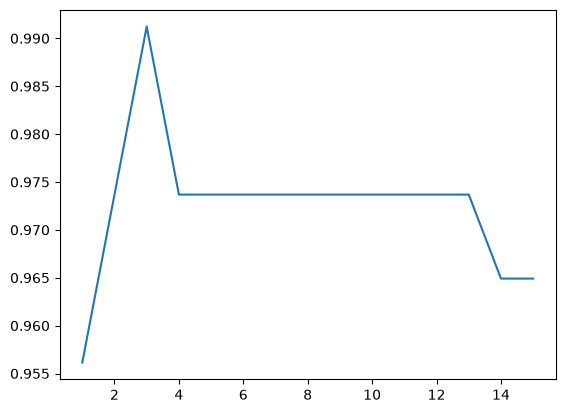

In [15]:
import matplotlib.pyplot as plt

plt.plot(range(1,16),scores)

## Step 16: Decision Boundary Visualization

Visualize how KNN draws decision boundaries in 2D space using the first two features of the breast cancer dataset.

This step is split into two parts:

- **Part 1 — Static Grid:** Side-by-side comparison of decision boundaries at K = 1, 2, 3, 5, 7, 10, 15, 20 with 5-fold CV accuracy shown in each title.
- **Part 2 — Interactive Explorer:** Slider-based interactive plot to explore any K value between 1 and 20.

**Key observations to look for:**
- **Low K (1–3):** Highly irregular, jagged boundaries → *overfitting*
- **Medium K (5–10):** Smoother boundaries → *balanced bias-variance*
- **High K (15–20):** Very smooth, generalised boundaries → *underfitting*

### How the Decision Boundary is Calculated

A KNN decision boundary is **not drawn explicitly** — it emerges from the prediction rule applied to every point in the feature space.

---

#### Step 1 — Predict the class for every point in the grid

For a query point $\mathbf{x} = (x_1, x_2)$, KNN finds its $K$ nearest training points $\mathcal{N}_K(\mathbf{x})$ and takes a **majority vote**:

$$\boxed{\hat{y}(\mathbf{x}) = \underset{c}{\arg\max} \sum_{i \in \mathcal{N}_K(\mathbf{x})} \mathbb{1}(y_i = c)}$$

| Symbol | Meaning |
|---|---|
| $\mathcal{N}_K(\mathbf{x})$ | The set of $K$ nearest neighbors of query point $\mathbf{x}$ |
| $\mathbb{1}(y_i = c)$ | Indicator: 1 if neighbor $i$ belongs to class $c$, else 0 |
| $\hat{y}(\mathbf{x})$ | Predicted class — whichever class gets the most votes |

---

#### Step 2 — Distance used to find neighbors

Neighbors are ranked by **Euclidean distance** in the scaled 2D feature space $(x_1, x_2)$:

$$\boxed{d(\mathbf{x}, \mathbf{x}_i) = \sqrt{(x_1 - x_{i1})^2 + (x_2 - x_{i2})^2}}$$

---

#### Step 3 — The boundary is where the vote is tied

The **decision boundary** is the set of all points $\mathbf{x}^*$ where two classes receive **equal votes**:

$$\boxed{\sum_{i \in \mathcal{N}_K(\mathbf{x}^*)} \mathbb{1}(y_i = \text{Malignant}) = \sum_{i \in \mathcal{N}_K(\mathbf{x}^*)} \mathbb{1}(y_i = \text{Benign})}$$

On one side of this line: Malignant wins. On the other side: Benign wins.

---

#### Step 4 — Build the mesh grid (what the code does)

```
For every point (x₁, x₂) on a fine grid covering the feature space:
    → find its K nearest training points
    → take majority vote  →  predict class
    → color that grid cell: pink (Malignant) or blue (Benign)

The boundary = the edge where the color changes
```

> **Note:** With $K = 1$, every training point becomes the center of its own Voronoi cell — the boundary is the perpendicular bisector between neighboring training points of different classes. As $K$ increases, the boundary smooths out because more votes are averaged.

---

#### Effect of K on the boundary

| K | Boundary shape | Bias | Variance |
|---|---|---|---|
| **1** | Extremely jagged — wraps tightly around every point | Low | High |
| **3–5** | Moderate smoothness | Balanced | Balanced |
| **10–20** | Very smooth, close to linear | High | Low |

### Part 1: Decision Boundaries at Different K Values

The plot below shows a **2 × 4 grid** of decision boundaries for K = 1, 2, 3, 5, 7, 10, 15, and 20.

Each subplot includes:
- **Background color:** Predicted region (pink = Malignant, blue = Benign)
- **Data points:** Dark red = Malignant (M), Dark blue = Benign (B)
- **Title:** K value and 5-fold cross-validation accuracy

This mirrors the style used for comparing model complexity across different hyperparameter settings.

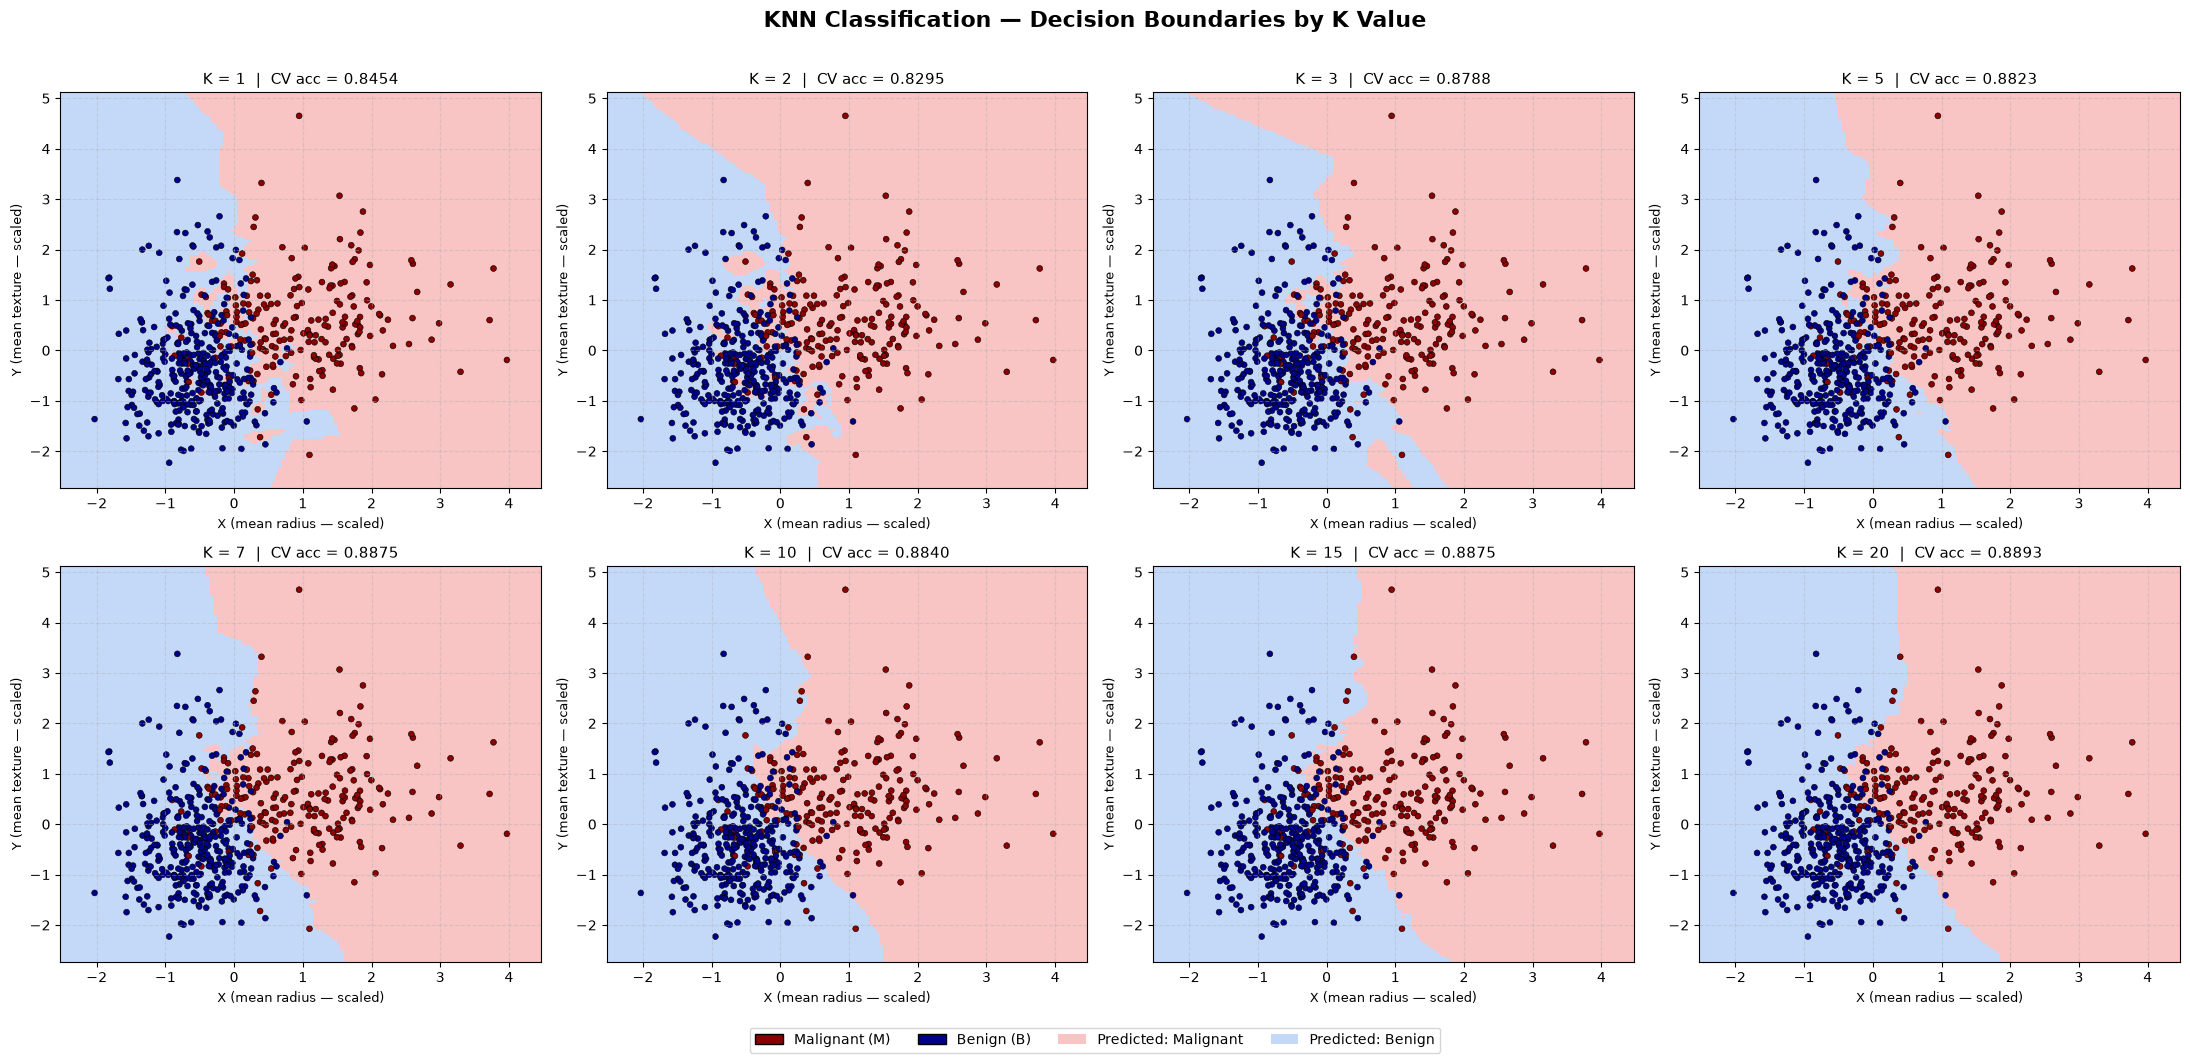

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import neighbors, datasets
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# ── Load and prepare data ──────────────────────────────────────────────────────
cancer = datasets.load_breast_cancer()
X_vis = StandardScaler().fit_transform(cancer.data[:, :2])
y_vis = cancer.target

# K values to compare (2 rows × 4 cols)
k_values = [1, 2, 3, 5, 7, 10, 15, 20]

# ── Color maps  (matches reference style: pink / blue regions) ────────────────
cmap_light = ListedColormap(['#F8C4C4', '#C4D8F8'])   # soft pink, soft blue
cmap_bold  = ListedColormap(['#8B0000', '#00008B'])   # dark red, dark blue

h = 0.05   # mesh step size

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle(
    'KNN Classification — Decision Boundaries by K Value',
    fontsize=16, fontweight='bold', y=1.01
)

for ax, k in zip(axes.ravel(), k_values):
    clf = neighbors.KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_vis, y_vis)

    # 5-fold cross-validation accuracy
    cv_acc = cross_val_score(clf, X_vis, y_vis, cv=5, scoring='accuracy').mean()

    # Build prediction mesh
    x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
    y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Decision region background
    ax.pcolormesh(xx, yy, Z, cmap=cmap_light, shading='auto')

    # Scatter training points
    ax.scatter(X_vis[:, 0], X_vis[:, 1],
               c=y_vis, cmap=cmap_bold,
               edgecolors='k', linewidths=0.4, s=18)

    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xlabel('X (mean radius — scaled)', fontsize=9)
    ax.set_ylabel('Y (mean texture — scaled)', fontsize=9)
    ax.set_title(f'K = {k}  |  CV acc = {cv_acc:.4f}', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.4)

# ── Shared legend ──────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#8B0000', edgecolor='k', label='Malignant (M)'),
    Patch(facecolor='#00008B', edgecolor='k', label='Benign (B)'),
    Patch(facecolor='#F8C4C4', edgecolor='none', label='Predicted: Malignant'),
    Patch(facecolor='#C4D8F8', edgecolor='none', label='Predicted: Benign'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4,
           fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.04))

plt.tight_layout()
plt.show()

---

### Part 2: Interactive Decision Boundary Explorer

Use the **slider below** to set any K value from 1 to 20 and instantly see how the decision boundary changes.

This is useful for:
- Developing **intuition** for the effect of K on boundary shape
- Spotting the transition from **overfitting → balanced → underfitting**
- Comparing with the static grid above to verify your understanding

> **Tip:** Try K = 1, then slowly increase it. Notice how the jagged boundary in the Malignant region gradually smooths out.

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn import neighbors, datasets
from sklearn.preprocessing import StandardScaler
from ipywidgets import interact, fixed

def load_data():
    cancer = datasets.load_breast_cancer()
    return cancer

def plot_decision_boundaries(n_neighbors, data, labels):
    h = .02
    cmap_light = ListedColormap(['orange', 'blue'])
    cmap_bold = ListedColormap(['darkorange', 'darkblue'])

    clf = neighbors.KNeighborsClassifier(n_neighbors)
    clf.fit(data, labels)

    x_min, x_max = data[:, 0].min() - 1, data[:, 0].max() + 1
    y_min, y_max = data[:, 1].min() - 1, data[:, 1].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])

    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(8, 6))
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

    plt.scatter(data[:, 0], data[:, 1], c=labels, cmap=cmap_bold, edgecolor='k', s=20)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(f'2-Class classification (k = {n_neighbors})')
    plt.show()

cancer = load_data()

# Use only the first two features and standardize them.
X = StandardScaler().fit_transform(cancer.data[:, :2])
y = cancer.target

# Interactive widget
interact(plot_decision_boundaries, n_neighbors=(1, 20), data=fixed(X), labels=fixed(y));

interactive(children=(IntSlider(value=10, description='n_neighbors', max=20, min=1), Output()), _dom_classes=(…

---

<p align="center">
  ⬅️ <strong>Previous:</strong> <a href="./13%20Class%20imbalance%2C%20ties%2C%20and%20edge%20cases.md">13 Class imbalance, ties, and edge cases</a>
</p>